In [2]:
!pip install -U sentence-transformers



[notice] A new release of pip is available: 25.1.1 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np
from bert_score import score
from sentence_transformers import SentenceTransformer, util
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv("C:\\Users\\temisola\\Final-Year-Project\\datasets\\yoruba_proverb_final_cleaned.csv")

In [5]:
print(df.columns.tolist())
print(df.shape)
df.head(3)

['entry_id', 'yoruba', 'english_literal', 'interpretation_gold', 'deepseek_translation', 'claude_translation', 'gemini_translation', 'mistral_translation', 'llama_translation', 'deepseek_interpretation', 'claude_interpretation', 'gemini_interpretation', 'mistral_interpretation', 'llama_interpretation']
(954, 14)


,entry_id,yoruba,english_literal,interpretation_gold,deepseek_translation,claude_translation,gemini_translation,mistral_translation,llama_translation,deepseek_interpretation,claude_interpretation,gemini_interpretation,mistral_interpretation,llama_interpretation
0,016beb1f83885794,Àgbéré àwòdì ní ńní òun ó jẹ ìgbín.,It is an overreaching kite that proposes to ea...,Know your limits.,The kite's talon says it will eat the snail.,The kite that carries snails says it will eat ...,The hawk's foolishness is that it thinks it wi...,The kite boasts that it will eat the snail.,The snail shell is what the snail eats.,This proverb warns against making empty boasts...,Someone who has access to or control over some...,It is foolish to attempt something impossible ...,It warns against overconfidence in one's abili...,One's circumstances or resources can be the so...
1,041e7cc871bfebac,A kì í kórira ọ̀fọ́n-ọ̀n ká finá bọ ahéré.,One does not so hate the bush rat that one set...,One should not destroy oneself simply to get a...,We do not hate the grinding stone and use fire...,One does not hate a wasp so much as to use fir...,One does not hate the buffalo so much as to se...,We do not gather dry twigs to set a hut on fire,We do not use a single rope to tie a bundle of...,Do not destroy something useful while expressi...,The cure should not be worse than the problem ...,One should not cause greater harm to oneself o...,One should not deliberately create or escalate...,Unity and cooperation are necessary to achieve...
2,04d43584d1d8404a,A kì í bọ òrìṣà lójú ọ̀fọ́n-ọ̀n; bó bá dalé...,One does not sacrifice to a god in the presenc...,Do not do things that might constitute temptat...,We do not worship the deity in the presence of...,One does not worship a deity in the presence o...,One does not worship an Orisha in the open; wh...,We do not worship the deity in the presence of...,We do not worship the god of the forest in the...,This proverb advises discretion and the import...,Sacred or important activities should not be p...,It is unwise to perform sacred rituals or reve...,"Laziness hinders progress, but persistence and...",One should respect the norms and conventions o...


In [6]:
interpretation_cols = [
    "deepseek_interpretation",
    "claude_interpretation",
    "gemini_interpretation",
    "mistral_interpretation",
    "llama_interpretation"
]

df_eval = df[["entry_id", "interpretation_gold"] + interpretation_cols].copy()

In [7]:
df_long = df_eval.melt(
    id_vars=["entry_id", "interpretation_gold"],
    value_vars=interpretation_cols,
    var_name="model",
    value_name="generated_interpretation"
)

In [8]:
df_long["model"] = df_long["model"].str.replace("_interpretation", "")

In [9]:
df_long = df_long.rename(columns={"interpretation_gold": "reference_interpretation"})

In [14]:
df_long["reference_interpretation"] = df_long["reference_interpretation"].astype(str).str.strip()
df_long["generated_interpretation"] = df_long["generated_interpretation"].astype(str).str.strip()

df_long = df_long[
    (df_long["reference_interpretation"] != "") &
    (df_long["generated_interpretation"] != "")
].reset_index(drop=True)

print(df_long.shape)
df_long.head()  

(4770, 4)


,entry_id,reference_interpretation,model,generated_interpretation
0,016beb1f83885794,Know your limits.,deepseek,This proverb warns against making empty boasts...
1,041e7cc871bfebac,One should not destroy oneself simply to get a...,deepseek,Do not destroy something useful while expressi...
2,04d43584d1d8404a,Do not do things that might constitute temptat...,deepseek,This proverb advises discretion and the import...
3,0524e60d4f486d54,"When a venerable person acts like a fool, few ...",deepseek,Silence in the face of wrongdoing can lead to ...
4,0584b5795ae7ccb8,A person who wants to be respected must respec...,deepseek,Unused resources or tools are neglected and lo...


In [15]:
preds = df_long["generated_interpretation"].tolist()
refs = df_long["reference_interpretation"].tolist()

P, R, F1 = score(preds, refs, lang="en", verbose=True)

df_long["bertscore_f1"] = F1.numpy()

Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


calculating scores...
computing bert embedding.


  0%|          | 0/90 [00:00<?, ?it/s]

computing greedy matching.


  0%|          | 0/75 [00:00<?, ?it/s]

done in 792.87 seconds, 6.02 sentences/sec


In [16]:
sbert_model = SentenceTransformer("all-MiniLM-L6-v2")

ref_emb = sbert_model.encode(df_long["reference_interpretation"].tolist(), convert_to_tensor=True)
gen_emb = sbert_model.encode(df_long["generated_interpretation"].tolist(), convert_to_tensor=True)

cos_scores = util.cos_sim(gen_emb, ref_emb).diagonal()

df_long["sbert_similarity"] = cos_scores.cpu().numpy()

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

c:\Users\temisola\AppData\Local\Programs\Python\Python39\lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\temisola\.cache\huggingface\hub\models--sentence-transformers--all-MiniLM-L6-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [20]:
summary = (
    df_long.groupby("model")[["bertscore_f1", "sbert_similarity"]]
    .mean()
    .reset_index()
    .sort_values(by="model", ascending=True)
)

summary

,model,bertscore_f1,sbert_similarity
0,claude,0.864288,0.317230
1,deepseek,0.862407,0.295761
2,gemini,0.867317,0.341300
3,llama,0.863869,0.263274
4,mistral,0.862088,0.307786


In [22]:
df_long.to_csv("../datasets/interpretation_fidelity_rowlevel.csv", index=False)
summary.to_csv("../datasets/interpretation_fidelity_summary.csv", index=False)

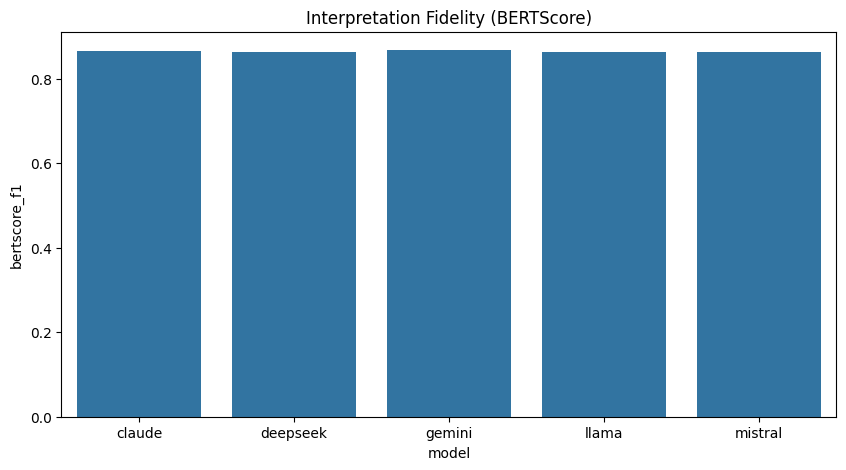

In [21]:
plt.figure(figsize=(10,5))
sns.barplot(data=summary, x="model", y="bertscore_f1")
plt.title("Interpretation Fidelity (BERTScore)")
plt.show()